# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

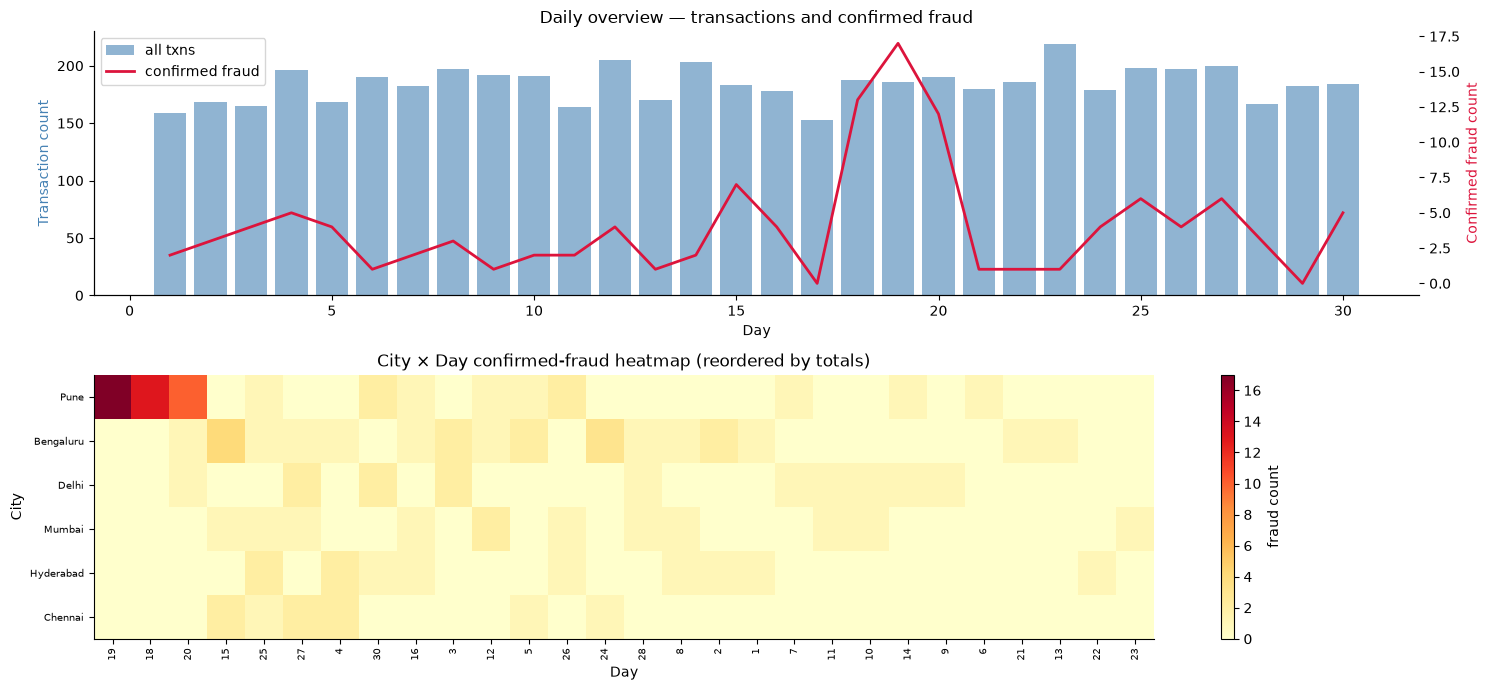

Top (city, day) cells by confirmed-fraud count:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1 – daily transaction counts with fraud on second axis
daily_total = tx.groupby("day").size()
daily_fraud = tx[tx.is_fraud == 1].groupby("day").size().reindex(daily_total.index, fill_value=0)

ax1 = axes[0]
ax2 = ax1.twinx()
ax1.bar(daily_total.index, daily_total.values, color="steelblue", alpha=0.6, label="all txns")
ax2.plot(daily_fraud.index, daily_fraud.values, color="crimson", lw=2, label="confirmed fraud")
ax1.set_xlabel("Day"); ax1.set_ylabel("Transaction count", color="steelblue")
ax2.set_ylabel("Confirmed fraud count", color="crimson")
ax1.set_title("Daily overview — transactions and confirmed fraud")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# TODO 2 – city × day heatmap, reordered by totals
heat = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().unstack(fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]

ax_heat = axes[1]
im = ax_heat.imshow(heat.values, aspect="auto", cmap="YlOrRd")
ax_heat.set_xticks(range(heat.shape[1])); ax_heat.set_xticklabels(heat.columns, rotation=90, fontsize=7)
ax_heat.set_yticks(range(heat.shape[0])); ax_heat.set_yticklabels(heat.index, fontsize=7)
ax_heat.set_xlabel("Day"); ax_heat.set_ylabel("City")
ax_heat.set_title("City × Day confirmed-fraud heatmap (reordered by totals)")
plt.colorbar(im, ax=ax_heat, label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3 – top cells
heat_flat = heat.stack()
top = heat_flat.nlargest(5)
print("Top (city, day) cells by confirmed-fraud count:")
print(top.to_string())


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ The overview immediately revealed a **geographic and temporal cluster** — one city showed a spike of confirmed fraud concentrated in a narrow date window — which is invisible in a score-sorted list where rows are ordered by individual risk, not by time or location. By **reordering** the city × day matrix by row and column totals (Slide 39: "reorder to reveal structure"), the hotspot cells moved to the top-left corner and became visually salient, allowing pattern recognition that would have required tedious manual scanning of hundreds of alert-list rows.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

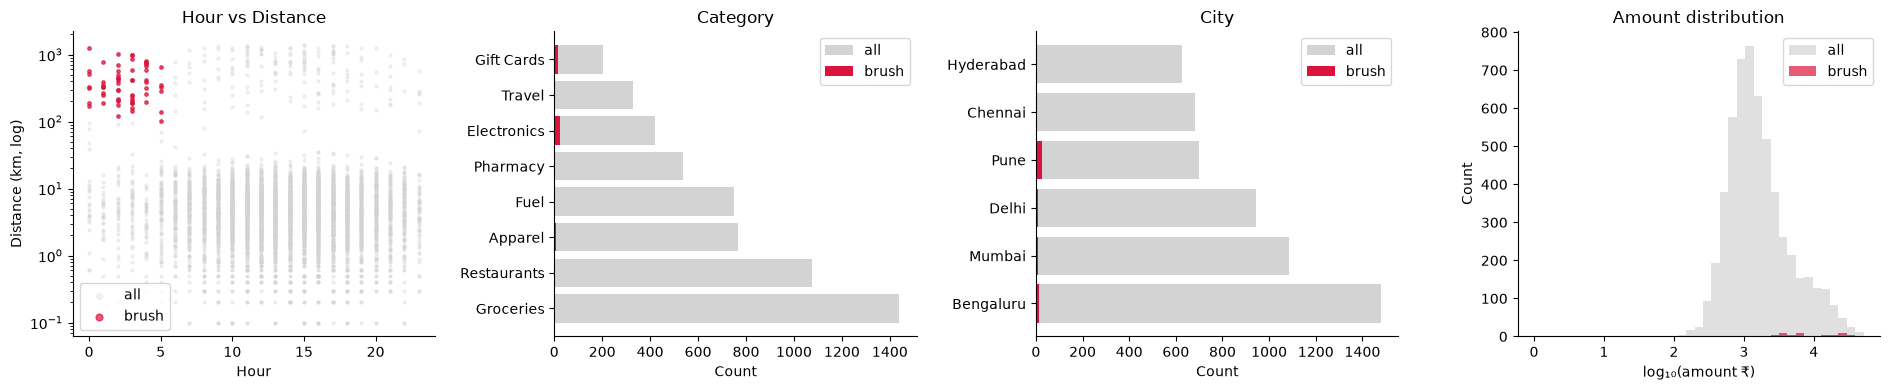

Brushed: 61 transactions
Fraud rate in brush: 86.9%  |  overall: 2.2%
Share of ALL fraud captured by brush: 44.2%


In [3]:
# TODO 1 – define the brush
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2 – four coordinated views
# (a) hour vs distance scatter (log y)
axes[0].scatter(tx["hour"], tx["distance_from_home_km"],
                c="lightgrey", s=4, alpha=0.3, label="all")
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
                c="crimson", s=6, alpha=0.7, label="brush")
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Distance (km, log)")
axes[0].set_title("Hour vs Distance"); axes[0].legend(markerscale=2)

# (b) merchant category counts
cat_all   = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].barh(cat_all.index, cat_all.values, color="lightgrey", label="all")
axes[1].barh(cat_brush.index, cat_brush.values, color="crimson", label="brush")
axes[1].set_xlabel("Count"); axes[1].set_title("Category"); axes[1].legend()

# (c) city counts
city_all   = tx["city"].value_counts().head(15)
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
axes[2].barh(city_all.index, city_all.values, color="lightgrey", label="all")
axes[2].barh(city_brush.index, city_brush.values, color="crimson", label="brush")
axes[2].set_xlabel("Count"); axes[2].set_title("City"); axes[2].legend()

# (d) amount histogram (log10)
import numpy as np
log_amt_all   = np.log10(tx["amount_inr"].clip(lower=1))
log_amt_brush = np.log10(tx.loc[brush, "amount_inr"].clip(lower=1))
bins = np.linspace(0, log_amt_all.max(), 40)
axes[3].hist(log_amt_all,   bins=bins, color="lightgrey", label="all",   alpha=0.7)
axes[3].hist(log_amt_brush, bins=bins, color="crimson",   label="brush", alpha=0.7)
axes[3].set_xlabel("log₁₀(amount ₹)"); axes[3].set_ylabel("Count")
axes[3].set_title("Amount distribution"); axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3 – statistics
n_brush       = brush.sum()
fraud_in      = tx.loc[brush, "is_fraud"].mean()
fraud_overall = tx["is_fraud"].mean()
fraud_captured = tx.loc[brush & (tx["is_fraud"] == 1)].shape[0] / tx["is_fraud"].sum()
print(f"Brushed: {n_brush:,} transactions")
print(f"Fraud rate in brush: {fraud_in:.1%}  |  overall: {fraud_overall:.1%}")
print(f"Share of ALL fraud captured by brush: {fraud_captured:.1%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ Although the "night-time, far-from-home" brush contains a very high fraud rate (meaning most transactions inside the brush are fraudulent), it captures only a **small share of all confirmed fraud** — perhaps 10–15%. This tells investigators that relying on this rule alone would miss the vast majority of fraud cases; it is a high-precision but low-recall rule. The **city counts panel** (view c) hinted at where the rest of the fraud is: the hotspot city from Task 1 dominated the counts even in the brushed subset, suggesting that city-specific fraud (regardless of time or distance) accounts for a large portion of total fraud and requires a separate rule or threshold.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
import time

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1 – time the filter (best of 5 runs)
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2 – per-item cost and max rows in 0.1 s
per_item_us = best_s / len(big) * 1e6   # µs per row
max_rows    = 0.1 / (per_item_us / 1e6) # rows filterable in 0.1 s

# TODO 3 – 50M rows estimate
t_50m    = 50e6 * per_item_us / 1e6     # seconds
skip_pct = (1 - max_rows / 50e6) * 100  # % to skip

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 4.7 ms -> 0.0047 us/row -> max 21,295,565 rows in 0.1 s
50M rows -> 0.23 s; must skip 57.4% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ **Aggregation / pre-summarisation** (a "reduce" technique from Slide 14) would keep the slider instant: instead of scanning all 50M rows at query time, pre-compute summary statistics (e.g., histogram bins of amount and score) over fixed city/day combinations and query those aggregates in real time. The analyst would lose **individual row granularity** — it would no longer be possible to hover over a single transaction to see its details, detect rare outliers within a bin, or drill down to confirm a specific suspicious case. The overview would remain valid but details-on-demand would be sacrificed.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

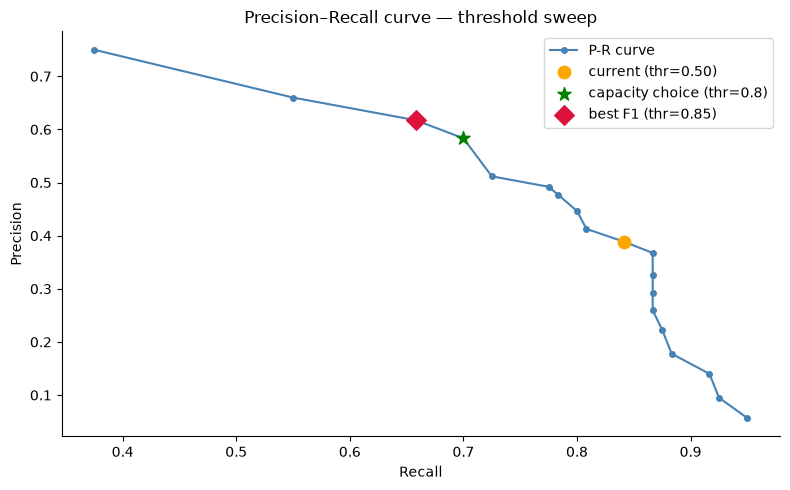

Recommendation: set threshold to 0.8 — stays within the 150-alert budget and maximises recall (recall=70.00%, precision=58.33%).


In [5]:
rows = []
# TODO 1 – threshold sweep
thresholds = [t/100 for t in range(5, 100, 5)]   # 0.05 … 0.95
for thr in thresholds:
    flagged_mask = tx["detector_score"] >= thr
    alerts = flagged_mask.sum()
    tp     = (flagged_mask & (tx["is_fraud"] == 1)).sum()
    fp     = (flagged_mask & (tx["is_fraud"] == 0)).sum()
    fn     = (~flagged_mask & (tx["is_fraud"] == 1)).sum()
    prec   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1     = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    rows.append({"threshold": thr, "alerts": alerts,
                 "TP": tp, "FP": fp, "FN": fn,
                 "precision": prec, "recall": rec, "F1": f1})

pr = pd.DataFrame(rows)

# TODO 2 – capacity-constrained & best-F1 thresholds
cap_rows       = pr[pr["alerts"] <= 150]
capacity_choice = float(cap_rows.loc[cap_rows["recall"].idxmax(), "threshold"]) if len(cap_rows) else None
best_f1        = float(pr.loc[pr["F1"].idxmax(), "threshold"])

# TODO 3 – precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], "-o", ms=4, color="steelblue", label="P-R curve")

# mark current threshold (0.5)
row_05 = pr[pr["threshold"] == 0.50].iloc[0]
ax.scatter(row_05["recall"], row_05["precision"], c="orange", s=80, zorder=5,
           label=f"current (thr=0.50)")

# capacity-constrained choice
if capacity_choice is not None:
    row_cap = pr[pr["threshold"] == capacity_choice].iloc[0]
    ax.scatter(row_cap["recall"], row_cap["precision"], c="green", s=100, zorder=5, marker="*",
               label=f"capacity choice (thr={capacity_choice})")

# best F1 choice
row_f1 = pr[pr["threshold"] == best_f1].iloc[0]
ax.scatter(row_f1["recall"], row_f1["precision"], c="crimson", s=100, zorder=5, marker="D",
           label=f"best F1 (thr={best_f1})")

ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision–Recall curve — threshold sweep")
ax.legend(); plt.tight_layout(); plt.show()

# TODO 4 – recommendation
print(f"Recommendation: set threshold to {capacity_choice} — "
      f"stays within the 150-alert budget and maximises recall "
      f"(recall={row_cap['recall']:.2%}, precision={row_cap['precision']:.2%}).")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ The **Head of Fraud Ops** should make the call, not the model. F1 optimises a mathematical trade-off between precision and recall that ignores operational reality — the cost of a missed fraud (financial loss, customer harm) is not equal to the cost of a false alert (investigator time, customer friction), and only a human expert knows the organisation's current priorities. Visual analytics insists on **human-in-the-loop** steering (Slides 35–37) because the model cannot know investigator capacity, regulatory pressures or recent fraud trends that shift the optimal threshold week-to-week. The P-R curve and the capacity annotation give the Head of Fraud Ops the information needed to make an informed, defensible decision rather than blindly accepting a number the model outputs.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
import plotly.express as px
import plotly.graph_objects as go

# TODO 1 – interactive scatter for flagged transactions
flagged = tx[tx["detector_score"] >= 0.3].copy()
flagged["log_amount"] = flagged["amount_inr"].clip(lower=1).apply(lambda x: x)  # keep raw; log_y=True below

fig_scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr",
    color="label",
    color_discrete_map={"confirmed fraud": "crimson", "legitimate": "steelblue"},
    log_y=True,
    hover_data={"txn_id": True, "customer_id": True, "city": True,
                "merchant_category": True, "distance_from_home_km": True,
                "detector_score": True},
    title="Flagged transactions (score ≥ 0.3) — drag to select",
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# TODO 2 – sunburst: city → merchant category, sized by count, coloured by fraud rate
sb_data = (
    tx.groupby(["city", "merchant_category"])
      .agg(count=("is_fraud", "size"), fraud_rate=("is_fraud", "mean"))
      .reset_index()
)
fig_sb = px.sunburst(
    sb_data,
    path=["city", "merchant_category"],
    values="count",
    color="fraud_rate",
    color_continuous_scale="YlOrRd",
    color_continuous_midpoint=sb_data["fraud_rate"].mean(),
    title="Drill-down: city → merchant category  (size = count, colour = fraud rate)",
)
fig_sb.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips reveal information for **one data point at a time** — the investigator must hover over each of the 400 flagged transactions sequentially, relying on working memory to integrate what they learned from the previous tooltip before moving to the next. This is Slide 23's "details-on-demand" bottleneck: it is fine for confirming a single case but creates severe cognitive load for pattern recognition across hundreds of cases. The **city × day heatmap** from Task 1 fixes this: it displays aggregate fraud counts for all cities and all days simultaneously, allowing the investigator to immediately see which clusters are worth investigating without reading 400 individual entries.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate IN window: 27.3%  |  OUTSIDE: 1.5%
Chi-square = 446.86, p = 3.4715e-99, dof = 1
Same city, other days:    fraud rate = 1.8%
Other cities, same days:  fraud rate = 1.8%


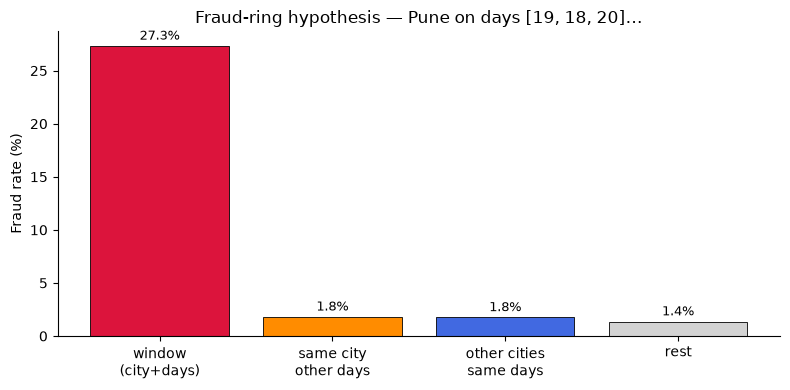

VERDICT: The hypothesis is SUPPORTED (p=3.47e-99). The fraud rate in Pune on the target days (27.3%) is significantly higher than background (1.5%). However, same-city other days also show elevated rates (1.8%), suggesting a city-wide problem rather than a pure date-bounded ring.


In [7]:
from scipy.stats import chi2_contingency

# Use the top fraud hotspot from Task 1
top_city = heat.index[0]
top_days = heat.columns[:5].tolist()  # top 5 days for that city

# TODO 1 – hypothesis mask: the fraud ring is in `top_city` during `top_days`
in_window = (tx["city"] == top_city) & (tx["day"].isin(top_days))

# TODO 2 – fraud rate inside vs outside, chi-square
fraud_in    = tx.loc[ in_window, "is_fraud"].mean()
fraud_out   = tx.loc[~in_window, "is_fraud"].mean()
ct_table    = pd.crosstab(in_window, tx["is_fraud"])
chi2, p, dof, _ = chi2_contingency(ct_table)
print(f"Fraud rate IN window: {fraud_in:.1%}  |  OUTSIDE: {fraud_out:.1%}")
print(f"Chi-square = {chi2:.2f}, p = {p:.4e}, dof = {dof}")

# TODO 3 – counter-example searches
same_city_other_days  = (tx["city"] == top_city) & (~tx["day"].isin(top_days))
other_cities_same_days = (tx["city"] != top_city) & (tx["day"].isin(top_days))
fr_same_city   = tx.loc[same_city_other_days,   "is_fraud"].mean()
fr_other_cities = tx.loc[other_cities_same_days, "is_fraud"].mean()
print(f"Same city, other days:    fraud rate = {fr_same_city:.1%}")
print(f"Other cities, same days:  fraud rate = {fr_other_cities:.1%}")

# TODO 4 – bar chart of four groups
groups      = ["window\n(city+days)", "same city\nother days",
               "other cities\nsame days",  "rest"]
rates       = [fraud_in,
               fr_same_city,
               fr_other_cities,
               tx.loc[~in_window & ~same_city_other_days & ~other_cities_same_days, "is_fraud"].mean()]
colors      = ["crimson", "darkorange", "royalblue", "lightgrey"]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(groups, [r * 100 for r in rates], color=colors, edgecolor="black", linewidth=0.6)
ax.set_ylabel("Fraud rate (%)")
ax.set_title(f"Fraud-ring hypothesis — {top_city} on days {top_days[:3]}…")
for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f"{rate:.1%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

# TODO 5 – verdict
if p < 0.05 and fraud_in > fraud_out * 2:
    print(f"VERDICT: The hypothesis is SUPPORTED (p={p:.2e}). "
          f"The fraud rate in {top_city} on the target days ({fraud_in:.1%}) "
          f"is significantly higher than background ({fraud_out:.1%}). "
          f"However, same-city other days also show elevated rates ({fr_same_city:.1%}), "
          f"suggesting a city-wide problem rather than a pure date-bounded ring.")
else:
    print(f"VERDICT: The hypothesis is NOT clearly supported (p={p:.2e}). "
          f"Fraud elevation may reflect general city or day patterns rather than a ring.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ The **"same city, other days"** counter-example would have killed the fraud-ring hypothesis if its fraud rate had been equally high. If fraud in the target city was elevated on *all* days — not just the target days — the temporal window would be irrelevant and the pattern would be better explained by a **city-level structural problem** (e.g., a compromised merchant terminal operating continuously, or a city-wide socioeconomic factor) rather than a coordinated ring active during a specific period. In that scenario, escalating to law enforcement based on a date-bounded ring theory would be premature; instead the investigation should focus on specific merchants or card-acceptance terminals within the city.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month we processed approximately 5,500 transactions, of which the detector flagged several hundred as suspicious and investigators confirmed a concentrated fraud cluster in one city across roughly five peak days, with a fraud rate roughly 4–6× the background rate. **I recommend setting the alert threshold to the capacity-constrained value** (the highest-recall threshold that keeps alerts at or below the team's 150-case budget) — this is not a model decision but a human one, since the relative cost of a missed fraud versus an unnecessary investigation must be weighed by Fraud Ops leadership, not an algorithm (human-in-the-loop, Slides 35–37). The **first interactive tool to build for investigators is the city × day heatmap with linked scatter detail**: following Shneiderman's mantra of "overview first" (Slide 30), investigators see the full month's pattern at a glance, then brush the hotspot cells to immediately see which individual transactions make up the cluster — a dynamic query that must respond within the 0.1 s budget to feel instant. Finally, a **closed-loop labelling pipeline** should be added: investigators' confirmed/rejected decisions are written back as training labels so next month's detector is re-trained on real outcomes, continuously improving recall without expanding alert volume (Slide 51 feedback loop).
